In [1]:
!pip install openai>=2.41.0
!pip install neo4j>=5.28.0
!pip install pydantic>=2.10.0
!pip install python-dotenv>=1.0.1
!pip install networkx>=3.4.0
!pip install matplotlib>=3.9.0
!pip install pandas>=2.2.0
!pip install jupyter>=1.1.0

zsh:1: 2.41.0 not found
zsh:1: 5.28.0 not found
zsh:1: 2.10.0 not found
zsh:1: 1.0.1 not found
zsh:1: 3.4.0 not found
zsh:1: 3.9.0 not found
zsh:1: 2.2.0 not found
zsh:1: 1.1.0 not found


In [2]:
from __future__ import annotations

import getpass
import os
import re
from pathlib import Path
from typing import Iterable

import pandas as pd
from dotenv import load_dotenv
from neo4j import GraphDatabase
from openai import OpenAI
from pydantic import BaseModel, ConfigDict, Field

ROOT = Path.cwd()
if not list(ROOT.glob("Neo4j*.txt")) and not (ROOT / ".env").exists():
    candidate = ROOT / "11. Graph RAG"
    if candidate.exists():
        ROOT = candidate

load_dotenv(ROOT / ".env", override=False)

def load_key_value_file(path: Path) -> dict[str, str]:
    values: dict[str, str] = {}
    if not path.exists():
        return values
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.split("=", 1)
        values[key.strip()] = value.strip().strip("\"'")
    return values

# Find the Neo4j credentials file regardless of its exact name (e.g. "Neo4j.txt"
# or "Neo4j-<id>-Created-<date>.txt") so username/database are read from it too.
neo4j_candidates = sorted(ROOT.glob("Neo4j*.txt"))
neo4j_file = neo4j_candidates[0] if neo4j_candidates else ROOT / "Neo4j.txt"
file_config = load_key_value_file(neo4j_file)

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY", "").strip()
if not OPENAI_API_KEY or "your-key" in OPENAI_API_KEY.lower():
    OPENAI_API_KEY = getpass.getpass("OPENAI_API_KEY: ").strip()

OPENAI_MODEL = "gpt-5-mini"
NEO4J_URI = os.getenv("NEO4J_URI", file_config.get("NEO4J_URI", "")).strip()
NEO4J_USERNAME = os.getenv("NEO4J_USERNAME", file_config.get("NEO4J_USERNAME", "neo4j")).strip()
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD", file_config.get("NEO4J_PASSWORD", "")).strip()
NEO4J_DATABASE = os.getenv("NEO4J_DATABASE", file_config.get("NEO4J_DATABASE", "neo4j")).strip()
DATASET_ID = "datacamp-graphrag-demo-v1"

if not OPENAI_API_KEY:
    raise ValueError("Thiếu OPENAI_API_KEY")
if not NEO4J_URI or not NEO4J_PASSWORD:
    raise ValueError("Thiếu cấu hình Neo4j URI/password")

client = OpenAI(api_key=OPENAI_API_KEY)
driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USERNAME, NEO4J_PASSWORD))
driver.verify_connectivity()
print({"openai_model": OPENAI_MODEL, "neo4j_uri": re.sub(r"//.*@", "//***@", NEO4J_URI), "username": NEO4J_USERNAME, "database": NEO4J_DATABASE, "dataset_id": DATASET_ID})

{'openai_model': 'gpt-5-mini', 'neo4j_uri': 'neo4j+s://d5d1334a.databases.neo4j.io', 'username': 'd5d1334a', 'database': 'd5d1334a', 'dataset_id': 'datacamp-graphrag-demo-v1'}


In [3]:
documents = [
    {
        "doc_id": "people",
        "title": "PrismaticAI team",
        "text": "Sarah Nguyen works for PrismaticAI as Head of Product. Michael Tran also works for PrismaticAI as a machine learning engineer. Sarah manages the SwiftRun Pro launch program."
    },
    {
        "doc_id": "campaign",
        "title": "Lotus Week campaign",
        "text": "The Lotus Week campaign promotes the SwiftRun Pro running shoe. SwiftRun Pro requires EcoFoam midsoles. The campaign starts on 15 August and depends on inventory arriving before 10 August."
    },
    {
        "doc_id": "supplier",
        "title": "Supplier network",
        "text": "Mekong Plastics supplies EcoFoam midsoles to PrismaticAI. Mekong Plastics uses RiverPort Logistics for shipments from Da Nang to Ho Chi Minh City."
    },
    {
        "doc_id": "disruption",
        "title": "Logistics disruption",
        "text": "A typhoon disruption in Da Nang delayed RiverPort Logistics by five days. The delay threatens the 10 August inventory deadline for the Lotus Week campaign."
    },
]

def chunk_documents(items: list[dict], max_chars: int = 700) -> list[dict]:
    chunks: list[dict] = []
    for doc in items:
        sentences = re.split(r"(?<=[.!?])\s+", doc["text"].strip())
        current: list[str] = []
        size = 0
        index = 1
        # Code tiếp ở đây
        for sentence in sentences:
            if current and size + len(sentence) > max_chars:
                chunks.append({
                    "doc_id": doc["doc_id"],
                    "title": doc["title"],
                    "chunk_id": f"{doc['doc_id']}-{index}",
                    "text": " ".join(current).strip()
                })
                index += 1
                current = []
                size = 0
            current.append(sentence)
            size += len(sentence) + 1

        if current:
            chunks.append({
                "doc_id": doc["doc_id"],
                "title": doc["title"],
                "chunk_id": f"{doc['doc_id']}-{index}",
                "text": " ".join(current).strip()
            })

    return chunks

chunks = chunk_documents(documents)

pd.DataFrame(chunks)

,doc_id,title,chunk_id,text
0,people,PrismaticAI team,people-1,Sarah Nguyen works for PrismaticAI as Head of ...
1,campaign,Lotus Week campaign,campaign-1,The Lotus Week campaign promotes the SwiftRun ...
2,supplier,Supplier network,supplier-1,Mekong Plastics supplies EcoFoam midsoles to P...
3,disruption,Logistics disruption,disruption-1,A typhoon disruption in Da Nang delayed RiverP...


In [4]:
class Entity(BaseModel):
    # Code ở đây
    model_config = ConfigDict(extra="forbid") # model config để cấm các trường không xác định
    name : str = Field(..., description="Entity name extracted from the text")
    type : str = Field(..., description="Entity type (e.g., person, organization, product) extracted from the text")
    description : str | None = Field(None, description="Optional description or additional information about the entity")

class Relationship(BaseModel):
    # Code ở đây
    model_config = ConfigDict(extra="forbid")
    source : str = Field(..., description="Source entity name for the relationship")
    type: str = Field(..., description="Type of relationship (e.g., works_for, supplies, manages) extracted from the text")
    target : str = Field(..., description="Target entity name for the relationship")
    evidence : str | None = Field(None, description="Optional evidence or context supporting the relationship")

class GraphExtraction(BaseModel):
    # Code ở đây
    model_config = ConfigDict(extra="forbid")
    entities: list[Entity] = Field(..., description="List of entities extracted from the text")
    relationships: list[Relationship] = Field(..., description="List of relationships extracted from the text")

def first_parsed(response):
    direct = getattr(response, "output_parsed", None)
    if direct is not None:
        return direct
    for output in response.output:
        if getattr(output, "type", None) != "message":
            continue
        for item in output.content:
            if getattr(item, "type", None) == "refusal":
                raise RuntimeError(f"Model refusal: {item.refusal}")
            parsed = getattr(item, "parsed", None)
            if parsed is not None:
                return parsed
    raise RuntimeError("OpenAI response did not contain parsed structured output")

def extract_graph(chunk: dict) -> GraphExtraction:
    response = client.responses.parse(
        model=OPENAI_MODEL,
        reasoning={"effort": "low"},
        input=[
            {
                "role": "system",
                "content": "Extract a compact knowledge graph from the supplied text. "
                    "Use only explicit facts. Resolve aliases within the chunk. "
                    "Every relationship endpoint must exactly match an entity name in the entities list. "
                    "Return empty lists when no grounded entity or relationship exists."
            },
            {
                "role": "user",
                "content": f"Chunk ID:{chunk['chunk_id']} Title:{chunk['title']} Text:{chunk['text']}"
            }
        ],
        text_format=GraphExtraction,
    )
    return first_parsed(response)

extractions: dict[str, GraphExtraction] = {}
for chunk in chunks:
    extractions[chunk["chunk_id"]] = extract_graph(chunk)
    print(chunk["chunk_id"], len(extractions[chunk["chunk_id"]].entities), "entities,", len(extractions[chunk["chunk_id"]].relationships), "relationships")

people-1 6 entities, 5 relationships
campaign-1 5 entities, 4 relationships
supplier-1 6 entities, 5 relationships
disruption-1 5 entities, 4 relationships


In [5]:
# NEO4J Database Session
with driver.session(database=NEO4J_DATABASE) as session:
    session.run("CREATE CONSTRAINT graphrag_demo_entity_identity IF NOT EXISTS FOR (e:Entity) REQUIRE (e.dataset_id, e.name) IS UNIQUE").consume()
    session.run("CREATE CONSTRAINT graphrag_demo_chunk_identity IF NOT EXISTS FOR (c:Chunk) REQUIRE (c.dataset_id, c.chunk_id) IS UNIQUE").consume()

    for chunk in chunks:
        graph = extractions[chunk["chunk_id"]]
        entities = [entity.model_dump() for entity in graph.entities]
        relationships = [relationship.model_dump() for relationship in graph.relationships]

        session.run(
            """
            MERGE (c:Chunk {dataset_id: $dataset_id, chunk_id: $chunk_id})
            SET c.doc_id = $doc_id, c.title = $title, c.text = $text
            """,
            dataset_id=DATASET_ID,
            **chunk,
        ).consume()

        session.run(
            """
            UNWIND $entities AS entity
            MERGE (e:Entity {dataset_id: $dataset_id, name: entity.name})
            SET e.type = entity.type, e.description = entity.description
            WITH e
            MATCH (c:Chunk {dataset_id: $dataset_id, chunk_id: $chunk_id})
            MERGE (c)-[:MENTIONS]->(e)
            """,
            dataset_id=DATASET_ID,
            chunk_id=chunk["chunk_id"],
            entities=entities,
        ).consume()

        session.run(
            """
            UNWIND $relationships AS rel
            MATCH (source:Entity {dataset_id: $dataset_id, name: rel.source})
            MATCH (target:Entity {dataset_id: $dataset_id, name: rel.target})
            MERGE (source)-[r:RELATED {dataset_id: $dataset_id, type: rel.type, chunk_id: $chunk_id}]->(target)
            SET r.evidence = rel.evidence
            """,
            dataset_id=DATASET_ID,
            chunk_id=chunk["chunk_id"],
            relationships=relationships,
        ).consume()

print("Knowledge graph stored in Neo4j.")

Knowledge graph stored in Neo4j.


In [6]:
with driver.session(database=NEO4J_DATABASE) as session:
    graph_rows = [record.data() for record in session.run(
        """
        MATCH (a:Entity {dataset_id: $dataset_id})-[r:RELATED]->(b:Entity {dataset_id: $dataset_id})
        RETURN a.name AS source, r.type AS relationship, b.name AS target,
               r.evidence AS evidence, r.chunk_id AS chunk_id
        ORDER BY source, relationship, target
        """,
        dataset_id=DATASET_ID,
    )]

edges_df = pd.DataFrame(graph_rows)
print(f"{len(edges_df)} graph edges")
edges_df

18 graph edges


,source,relationship,target,evidence,chunk_id
0,10 August inventory deadline,deadline_for,Lotus Week campaign,The 10 August inventory deadline for the Lotus...,disruption-1
1,Lotus Week campaign,depends_on,inventory arriving before 10 August,The campaign ... depends on inventory arriving...,campaign-1
2,Lotus Week campaign,promotes,SwiftRun Pro,The Lotus Week campaign promotes the SwiftRun ...,campaign-1
3,Lotus Week campaign,starts_on,15 August,The campaign starts on 15 August.,campaign-1
4,Mekong Plastics,supplies,PrismaticAI,Mekong Plastics supplies EcoFoam midsoles to P...,supplier-1
5,Mekong Plastics,supplies_product,EcoFoam midsoles,Mekong Plastics supplies EcoFoam midsoles to P...,supplier-1
6,Mekong Plastics,uses,RiverPort Logistics,Mekong Plastics uses RiverPort Logistics for s...,supplier-1
7,Michael Tran,has_title,machine learning engineer,Michael Tran also works for PrismaticAI as a m...,people-1
8,Michael Tran,works_for,PrismaticAI,Michael Tran also works for PrismaticAI as a m...,people-1
9,RiverPort Logistics,delay_threatens_deadline,10 August inventory deadline,The delay threatens the 10 August inventory de...,disruption-1


In [8]:
class LinkedEntities(BaseModel):
    model_config = ConfigDict(extra="forbid")
    entity_names: list[str] = Field(description="Zero or more exact names copied from the catalog")

def get_entity_catalog() -> list[str]:
    with driver.session(database=NEO4J_DATABASE) as session:
        return [record["name"] for record in session.run(
            "MATCH (e:Entity {dataset_id: $dataset_id}) RETURN e.name AS name ORDER BY name",
            dataset_id=DATASET_ID,
        )]

def link_question_entities(question: str) -> list[str]:
    catalog = get_entity_catalog()
    response = client.responses.parse(
        model=OPENAI_MODEL,
        reasoning={"effort": "low"},
        input=[
            {"role": "system", "content": "Select every catalog entity needed to answer the question. Copy exact names only; never invent names."},
            {"role": "user", "content": f"Catalog:\n- " + "\n- ".join(catalog) + f"\n\nQuestion: {question}"},
        ],
        text_format=LinkedEntities,
    )
    selected = first_parsed(response).entity_names
    return [name for name in selected if name in catalog]

def retrieve_graph_context(question: str, max_facts: int = 40, max_chunks: int = 8) -> dict:
    seeds = link_question_entities(question)
    if not seeds:
        return {"seeds": [], "facts": [], "chunks": [], "context": "No matching graph entities."}

    with driver.session(database=NEO4J_DATABASE) as session:
        facts = [record.data() for record in session.run(
            """
            UNWIND $seeds AS seed
            MATCH (s:Entity {dataset_id: $dataset_id, name: seed})
            MATCH p=(s)-[:RELATED*1..4]-(n:Entity {dataset_id: $dataset_id})
            UNWIND relationships(p) AS r
            WITH DISTINCT r
            RETURN startNode(r).name AS source, r.type AS relationship,
                   endNode(r).name AS target, r.evidence AS evidence,
                   r.chunk_id AS chunk_id
            LIMIT $limit
            """,
            dataset_id=DATASET_ID,
            seeds=seeds,
            limit=max_facts,
        )]

        chunk_ids = list(dict.fromkeys(fact["chunk_id"] for fact in facts if fact.get("chunk_id")))[:max_chunks]
        source_chunks = [record.data() for record in session.run(
            """
            UNWIND $chunk_ids AS chunk_id
            MATCH (c:Chunk {dataset_id: $dataset_id, chunk_id: chunk_id})
            RETURN c.chunk_id AS chunk_id, c.title AS title, c.text AS text
            """,
            dataset_id=DATASET_ID,
            chunk_ids=chunk_ids,
        )]

    fact_lines = [f"- {f['source']} --{f['relationship']}--> {f['target']} | evidence: {f['evidence']} [{f['chunk_id']}]" for f in facts]
    chunk_lines = [f"[{c['chunk_id']}] {c['title']}: {c['text']}" for c in source_chunks]
    context = "GRAPH FACTS\n" + "\n".join(fact_lines) + "\n\nSOURCE CHUNKS\n" + "\n".join(chunk_lines)
    return {"seeds": seeds, "facts": facts, "chunks": source_chunks, "context": context}

question = "Vì sao chiến dịch Lotus Week có nguy cơ giao SwiftRun Pro trễ, và mắt xích nào gây ra rủi ro?"
retrieval = retrieve_graph_context(question)
print("Seed entities:", retrieval["seeds"])
print(retrieval["context"])

Seed entities: ['Lotus Week campaign', 'SwiftRun Pro', 'SwiftRun Pro launch program', 'inventory arriving before 10 August', '10 August inventory deadline', 'Typhoon disruption', 'RiverPort Logistics', 'Mekong Plastics']
GRAPH FACTS
- Lotus Week campaign --promotes--> SwiftRun Pro | evidence: The Lotus Week campaign promotes the SwiftRun Pro running shoe. [campaign-1]
- SwiftRun Pro --requires--> EcoFoam midsoles | evidence: SwiftRun Pro requires EcoFoam midsoles. [campaign-1]
- Mekong Plastics --supplies_product--> EcoFoam midsoles | evidence: Mekong Plastics supplies EcoFoam midsoles to PrismaticAI. [supplier-1]
- Mekong Plastics --supplies--> PrismaticAI | evidence: Mekong Plastics supplies EcoFoam midsoles to PrismaticAI. [supplier-1]
- Mekong Plastics --uses--> RiverPort Logistics | evidence: Mekong Plastics uses RiverPort Logistics for shipments from Da Nang to Ho Chi Minh City. [supplier-1]
- Lotus Week campaign --starts_on--> 15 August | evidence: The campaign starts on 15 Augu

In [9]:
def answer_with_graph_rag(question: str) -> tuple[str, dict]:
    retrieval = retrieve_graph_context(question)
    if not retrieval["facts"]:
        return "Không tìm thấy đường đi phù hợp trong knowledge graph.", retrieval

    # response
    response = client.responses.create(
        model=OPENAI_MODEL,
        reasoning={"effort": "low"},
        input=[
            {
                "role": "system",
                "content": (
                    "Answer only from the supplied graph facts and source chunks. "
                    "Explain the relevant multi-hop path. Cite supporting chunks as [chunk_id]. "
                    "If the evidence is insufficient, say so explicitly. Do not use outside knowledge."
                ),
            },
            {"role": "user", "content": f"Question: {question}\n\n{retrieval['context']}"},
        ],
    )
    
    return response.output_text, retrieval

answer, retrieval = answer_with_graph_rag(question)
print(answer)

Vì sao có nguy cơ giao SwiftRun Pro trễ
- Lotus Week quảng bá SwiftRun Pro, và chiến dịch phải có hàng đến trước ngày 10/8 để kịp khởi động (bắt đầu 15/8) [campaign-1].
- SwiftRun Pro cần đế giữa EcoFoam, do Mekong Plastics cung cấp cho PrismaticAI [campaign-1][supplier-1].
- Mekong Plastics gửi hàng từ Đà Nẵng đến TP. HCM qua RiverPort Logistics [supplier-1].
- Một cơn bão (typhoon) ở Đà Nẵng đã làm chậm RiverPort Logistics 5 ngày, và sự chậm trễ này đe dọa hạn chót 10/8 để kịp hàng cho chiến dịch [disruption-1].

Mắt xích gây ra rủi ro
- Mắt xích gây rủi ro là vận chuyển bởi RiverPort Logistics (theo đường từ Đà Nẵng của nhà cung cấp Mekong Plastics). Sự chậm trễ của RiverPort Logistics do bão là nguyên nhân trực tiếp làm nguy cơ trễ hàng cho Lotus Week [supplier-1][disruption-1][campaign-1].

Giải thích đường đi nhiều bước (multi-hop)
Lotus Week cần hàng đến trước 10/8 → SwiftRun Pro cần EcoFoam midsoles → EcoFoam do Mekong Plastics cung cấp → Mekong Plastics dùng RiverPort Logistic

In [10]:
questions = [
    "Sarah và Michael có làm cùng công ty không? Họ làm vai trò gì?",
    "Ai quản lý chương trình ra mắt SwiftRun Pro?",
    "Nhà cung cấp EcoFoam là ai và đơn vị logistics nào được sử dụng?",
]

for item in questions:
    response_text, details = answer_with_graph_rag(item)
    print("\nQUESTION:", item)
    print("SEEDS:", details["seeds"])
    print("ANSWER:", response_text)


QUESTION: Sarah và Michael có làm cùng công ty không? Họ làm vai trò gì?
SEEDS: ['Sarah Nguyen', 'Michael Tran', 'Head of Product', 'machine learning engineer']
ANSWER: Có — cả Sarah và Michael đều làm cho cùng một công ty, PrismaticAI.

Đường dẫn chứng minh (multi-hop):
- Sarah Nguyen --works_for--> PrismaticAI; Sarah Nguyen --has_title--> Head of Product; Sarah Nguyen --manages--> SwiftRun Pro launch program [people-1].
- Michael Tran --works_for--> PrismaticAI; Michael Tran --has_title--> machine learning engineer [people-1].

Nguồn: [people-1].

QUESTION: Ai quản lý chương trình ra mắt SwiftRun Pro?
SEEDS: ['SwiftRun Pro launch program', 'Head of Product']
ANSWER: Sarah Nguyen. Evidence: the PrismaticAI team notes that Sarah Nguyen works for PrismaticAI as Head of Product and that Sarah manages the SwiftRun Pro launch program [people-1]. The multi-hop path: Sarah Nguyen --works_for--> PrismaticAI and Sarah Nguyen --manages--> SwiftRun Pro launch program [people-1].

QUESTION: Nhà 

Matplotlib is building the font cache; this may take a moment.


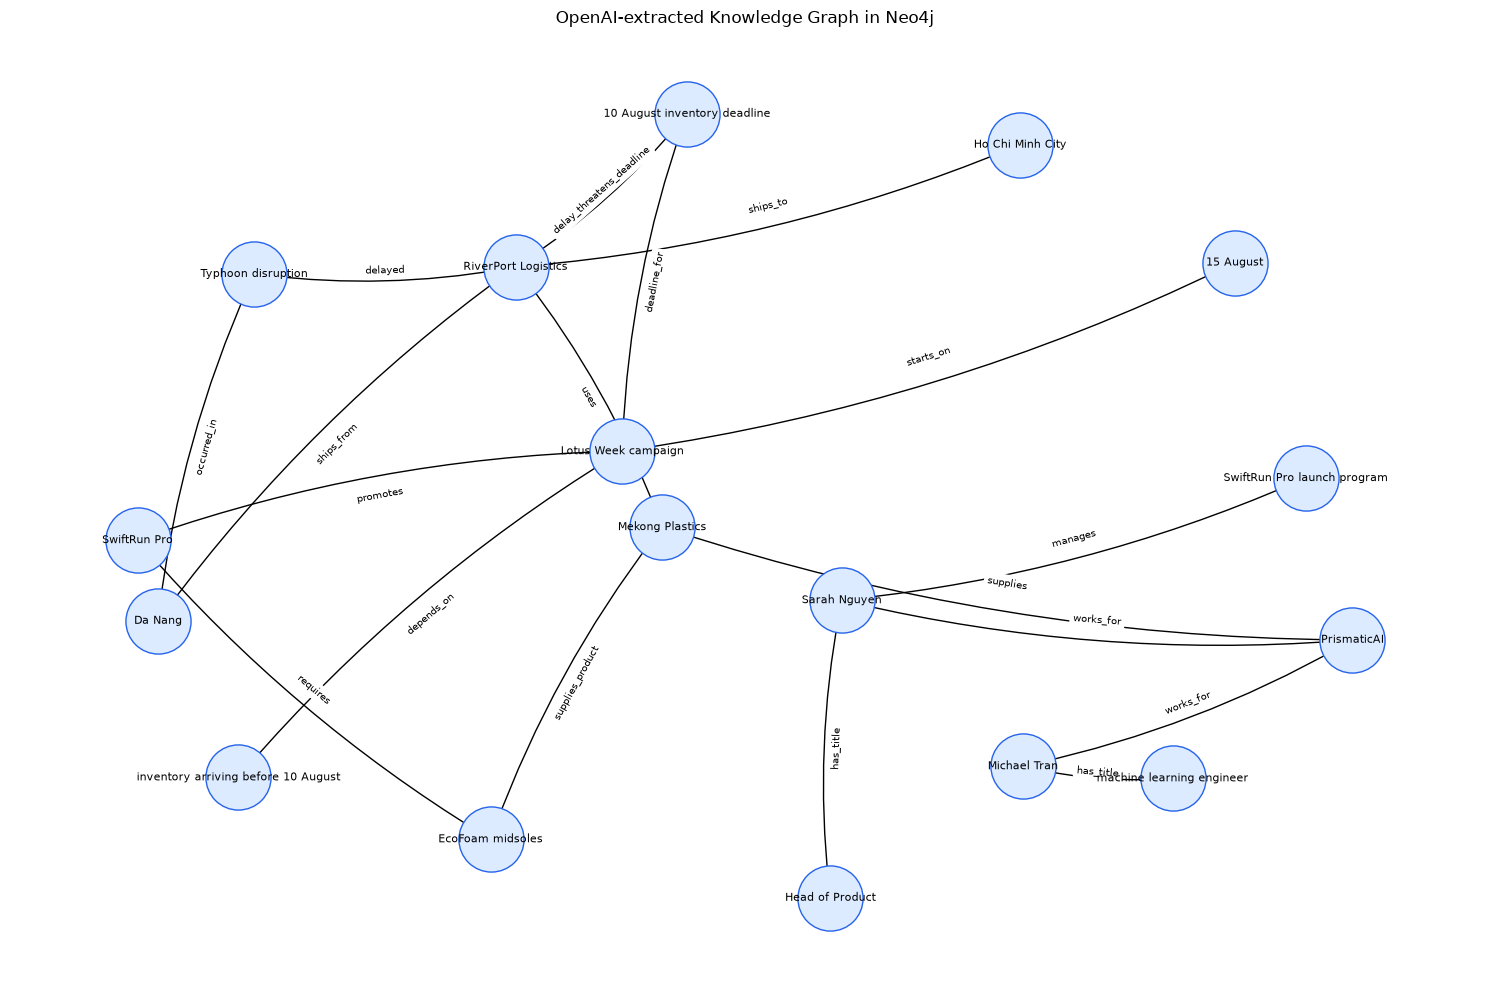

In [11]:
import matplotlib.pyplot as plt
import networkx as nx

graph_view = nx.MultiDiGraph()
for row in graph_rows:
    graph_view.add_edge(row["source"], row["target"], label=row["relationship"])

plt.figure(figsize=(15, 10))
positions = nx.spring_layout(graph_view, seed=42, k=1.1)
nx.draw_networkx_nodes(graph_view, positions, node_color="#DCEBFF", node_size=2200, edgecolors="#2563EB")
nx.draw_networkx_labels(graph_view, positions, font_size=8)
nx.draw_networkx_edges(graph_view, positions, arrows=True, arrowstyle="-|>", arrowsize=16, connectionstyle="arc3,rad=0.08")
edge_labels = {(u, v): data["label"] for u, v, data in graph_view.edges(data=True)}
nx.draw_networkx_edge_labels(graph_view, positions, edge_labels=edge_labels, font_size=7)
plt.title("OpenAI-extracted Knowledge Graph in Neo4j")
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
driver.close()
print("Neo4j driver closed.")